# LeetCode #295: Find Median from Data Stream

https://leetcode.com/problems/find-median-from-data-stream/

## Comparison of Approaches
| Approach | Time (add/find) | Space |
|---|---|---|
| Two Heaps ★ | O(log n) / O(1) | O(n) |
| Sorted List + Binary Search | O(n) / O(1) | O(n) |
| Balanced BST | O(log n) / O(log n) | O(n) |

## Understanding the Methods
### Two Heaps (Optimal)
Maintain a max-heap for the lower half and a min-heap for the upper half. Balance them so that the max-heap has at most one more element. The median is either the top of the max-heap (odd count) or the average of both tops (even count). Each insertion takes O(log n) and finding the median takes O(1).

### Sorted List + Binary Search
Keep a sorted list. Insert using binary search to find position, but shifting elements takes O(n).

### Balanced BST
Use a self-balancing BST with order statistics. More complex to implement but theoretically O(log n) for both operations.

## Solutions

### C#

In [ ]:
public class MedianFinder {
    private PriorityQueue<int, int> small = new();  // max-heap (negate)
    private PriorityQueue<int, int> large = new();  // min-heap

    public void AddNum(int num) {
        small.Enqueue(num, -num);
        int val = small.Dequeue();
        large.Enqueue(val, val);
        if (large.Count > small.Count) {
            int v = large.Dequeue();
            small.Enqueue(v, -v);
        }
    }

    public double FindMedian() {
        if (small.Count > large.Count)
            return small.Peek();
        return (small.Peek() + large.Peek()) / 2.0;
    }
}

### Python

In [ ]:
import heapq

class MedianFinder:
    def __init__(self):
        self.small = []  # max-heap (negated)
        self.large = []  # min-heap

    def addNum(self, num: int) -> None:
        heapq.heappush(self.small, -num)
        heapq.heappush(self.large, -heapq.heappop(self.small))
        if len(self.large) > len(self.small):
            heapq.heappush(self.small, -heapq.heappop(self.large))

    def findMedian(self) -> float:
        if len(self.small) > len(self.large):
            return -self.small[0]
        return (-self.small[0] + self.large[0]) / 2.0

### Go

In [ ]:
import "container/heap"

type MinHeap []int
func (h MinHeap) Len() int           { return len(h) }
func (h MinHeap) Less(i, j int) bool  { return h[i] < h[j] }
func (h MinHeap) Swap(i, j int)       { h[i], h[j] = h[j], h[i] }
func (h *MinHeap) Push(x interface{}) { *h = append(*h, x.(int)) }
func (h *MinHeap) Pop() interface{} {
    old := *h; n := len(old); x := old[n-1]; *h = old[:n-1]; return x
}

type MaxHeap []int
func (h MaxHeap) Len() int           { return len(h) }
func (h MaxHeap) Less(i, j int) bool  { return h[i] > h[j] }
func (h MaxHeap) Swap(i, j int)       { h[i], h[j] = h[j], h[i] }
func (h *MaxHeap) Push(x interface{}) { *h = append(*h, x.(int)) }
func (h *MaxHeap) Pop() interface{} {
    old := *h; n := len(old); x := old[n-1]; *h = old[:n-1]; return x
}

type MedianFinder struct {
    small MaxHeap
    large MinHeap
}

func Constructor() MedianFinder {
    return MedianFinder{}
}

func (mf *MedianFinder) AddNum(num int) {
    heap.Push(&mf.small, num)
    heap.Push(&mf.large, heap.Pop(&mf.small))
    if mf.large.Len() > mf.small.Len() {
        heap.Push(&mf.small, heap.Pop(&mf.large))
    }
}

func (mf *MedianFinder) FindMedian() float64 {
    if mf.small.Len() > mf.large.Len() {
        return float64(mf.small[0])
    }
    return float64(mf.small[0]+mf.large[0]) / 2.0
}

### Rust

In [ ]:
use std::collections::BinaryHeap;
use std::cmp::Reverse;

struct MedianFinder {
    small: BinaryHeap<i32>,           // max-heap
    large: BinaryHeap<Reverse<i32>>,  // min-heap
}

impl MedianFinder {
    fn new() -> Self {
        MedianFinder {
            small: BinaryHeap::new(),
            large: BinaryHeap::new(),
        }
    }

    fn add_num(&mut self, num: i32) {
        self.small.push(num);
        self.large.push(Reverse(self.small.pop().unwrap()));
        if self.large.len() > self.small.len() {
            self.small.push(self.large.pop().unwrap().0);
        }
    }

    fn find_median(&self) -> f64 {
        if self.small.len() > self.large.len() {
            *self.small.peek().unwrap() as f64
        } else {
            (*self.small.peek().unwrap() as f64 + self.large.peek().unwrap().0 as f64) / 2.0
        }
    }
}

## Example Scenarios

### 1. Common Case — Odd Count, Single Middle
**Input:** `addNum(1), addNum(2), addNum(3); findMedian()`
The max-heap (lower half) holds $\{1, 2\}$ and the min-heap (upper half) holds $\{3\}$. With an odd total, the median is the lower heap's top: $2$.

### 2. Slightly Complex — Even Count, Average of Tops
**Input:** `addNum(5), addNum(2), addNum(8), addNum(1); findMedian()`
Out-of-order inserts still balance to lower $\{1, 2\}$ and upper $\{5, 8\}$. Even total &rarr; average the two tops: $(2+5)/2 = 3.5$.

### 3. Edge Case: Time — Growing Stream
**Input:** `addNum(1..7); findMedian()`
Each insertion is $O(\log n)$ via the heaps. After seven values, lower $= \{1,2,3,4\}$, upper $= \{5,6,7\}$, median $= 4$.

### 4. Edge Case: Space — Repeated Values
**Input:** `addNum(2), addNum(2); findMedian()`
Duplicates are fine: one $2$ sits in each heap. Even total &rarr; median $= (2+2)/2 = 2.0$.

### 5. Almost-Impossible but Plausible — Extreme Range
**Input:** `addNum(-10), addNum(10), addNum(0), addNum(1000000), addNum(-1000000); findMedian()`
Values span $\pm 10^6$, but the heaps only compare, never sum, so magnitude is irrelevant. Lower $= \{-10^6, -10, 0\}$, upper $= \{10, 10^6\}$, median $= 0$.


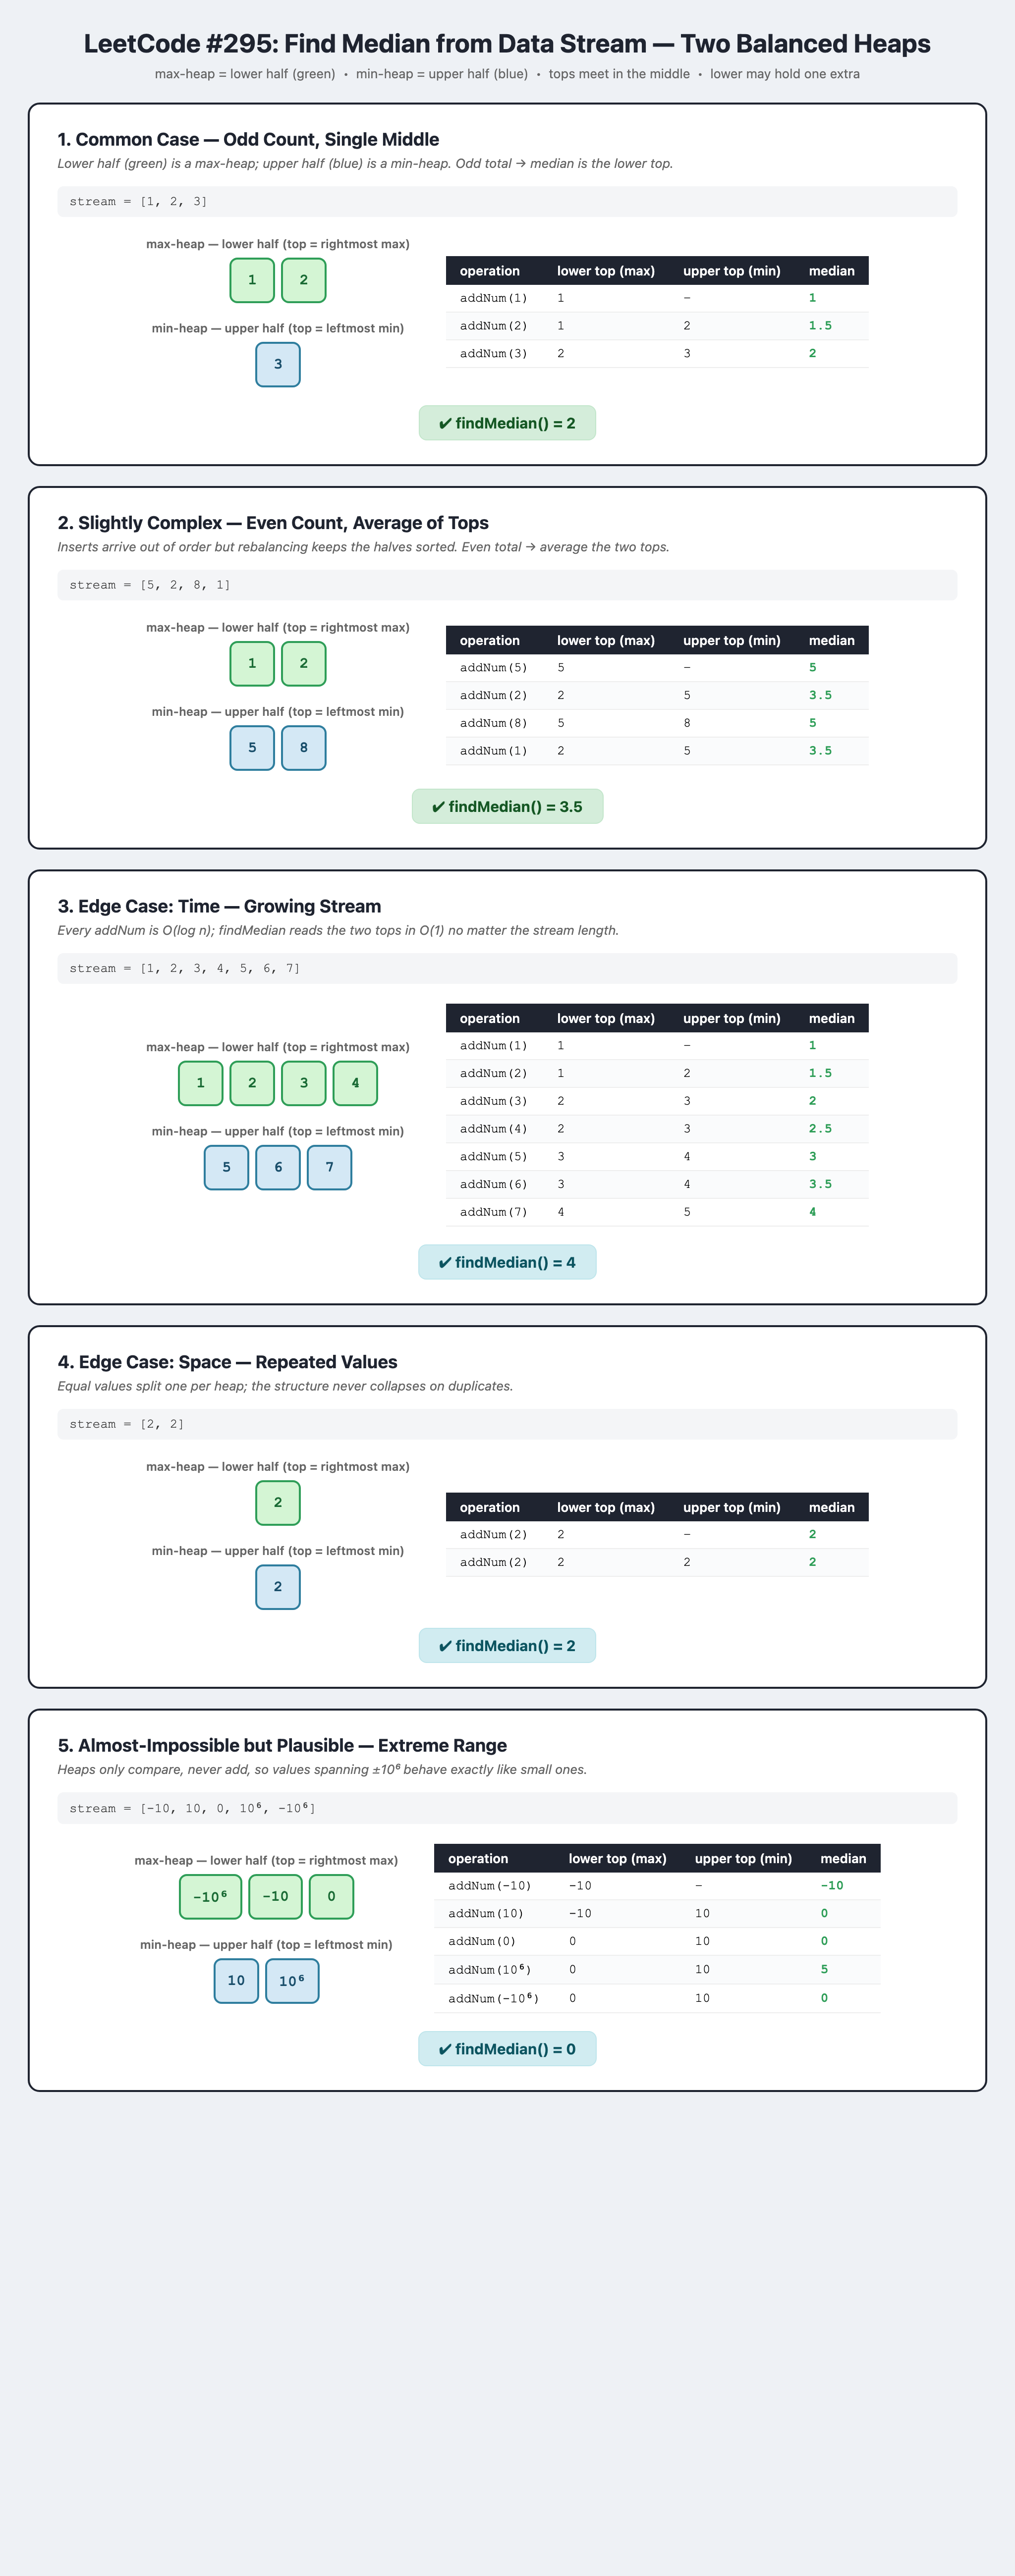